# 7. Harris Edge & Corner Detection

## Table of Contents
1. [Libraries](#libraries)
2. [Color image to Grayscale conversion](#grayscale)
3. [Spatial derivative calculation](#spatial)
4. [Structure tensor setup](#tensor)
5. [Harris response calculation](#response)
6. [Find edges and corners using R](#find)

## Equipo 11
## Alumnos
#### Hector Gerardo Paredes Castillo A01796892
#### Andres Marcelo Fernandez Loredo A01281054
#### Jose Angel Barajas Flores A01797221
#### Gilberto Valencia Acosta A01273602


## Importing Libraries <a class="anchor" id="libraries" ></a>

In [1]:
import cv2
import matplotlib.pyplot as plt
from scipy import signal as sig
import numpy as np
from scipy.ndimage.filters import convolve

/tmp/ipykernel_155832/1510717638.py:5: DeprecationWarning: Please import `convolve` from the `scipy.ndimage` namespace; the `scipy.ndimage.filters` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.ndimage.filters import convolve


## 1. Color to Grayscale <a class="anchor" id="grayscale" ></a>

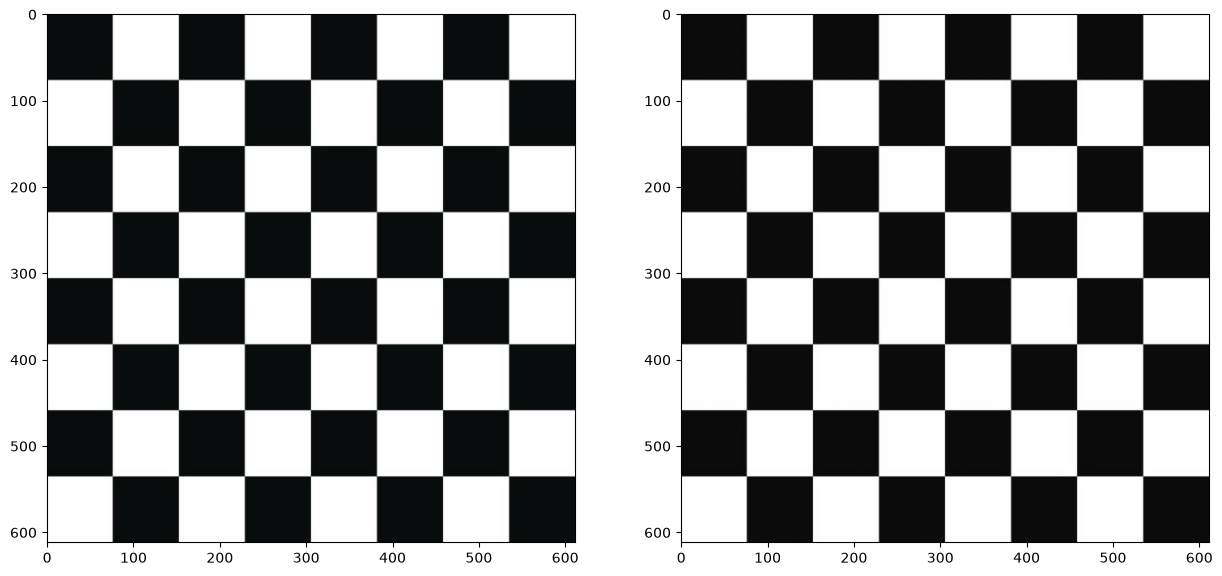

In [2]:
img = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/chessboard.jpg')
img_color = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_color)
plt.subplot(1, 2, 2)
plt.imshow(img_gray, cmap="gray")

## 2. Spatial derivative calculation <a class="anchor" id="spatial" ></a>

In [3]:
def gradient_x(imggray):
    ##Sobel operator kernels.
    kernel_x = np.array([[-1, 0, 1],[-2, 0, 2],[-1, 0, 1]])
    return sig.convolve2d(imggray, kernel_x, mode='same')

def gradient_y(imggray):
    kernel_y = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])
    return sig.convolve2d(imggray, kernel_y, mode='same')

I_x = gradient_x(img_gray)
I_y = gradient_y(img_gray)

## 3. Structure tensor setup <a class="anchor" id="tensor" ></a>

In [5]:
def gaussian_kernel(size, sigma=1):
    size = int(size) // 2
    x, y = np.mgrid[-size:size+1, -size:size+1]
    normal = 1 / (2.0 * np.pi * sigma**2)
    g =  np.exp(-((x**2 + y**2) / (2.0*sigma**2))) * normal
    return g


Ixx = convolve(I_x**2, gaussian_kernel(3, 1))
Ixy = convolve(I_y*I_x, gaussian_kernel(3, 1))
Iyy = convolve(I_y**2, gaussian_kernel(3, 1))

## 4. Harris response calculation <a class="anchor" id="response" ></a>

In [6]:
k = 0.05

# determinant
detA = Ixx * Iyy - Ixy ** 2

# trace
traceA = Ixx + Iyy
    
harris_response = detA - k * traceA ** 2

In [7]:
img_gray.shape

(612, 612)

In [8]:
window_size = 3
offset = window_size//2
width, height = img_gray.shape

for y in range(offset, height-offset):
    for x in range(offset, width-offset):
        Sxx = np.sum(Ixx[y-offset:y+1+offset, x-offset:x+1+offset])
        Syy = np.sum(Iyy[y-offset:y+1+offset, x-offset:x+1+offset])
        Sxy = np.sum(Ixy[y-offset:y+1+offset, x-offset:x+1+offset])

In [9]:
#Find determinant and trace, use to get corner response
det = (Sxx * Syy) - (Sxy**2)
trace = Sxx + Syy
r = det - k*(trace**2)

## 5. Find edges and corners using R <a class="anchor" id="find" ></a>

In [10]:
img_copy_for_corners = np.copy(img)
img_copy_for_edges = np.copy(img)

for rowindex, response in enumerate(harris_response):
    for colindex, r in enumerate(response):
        if r > 0:
            # this is a corner
            img_copy_for_corners[rowindex, colindex] = [255,0,0]
        elif r < 0:
            # this is an edge
            img_copy_for_edges[rowindex, colindex] = [0,255,0]

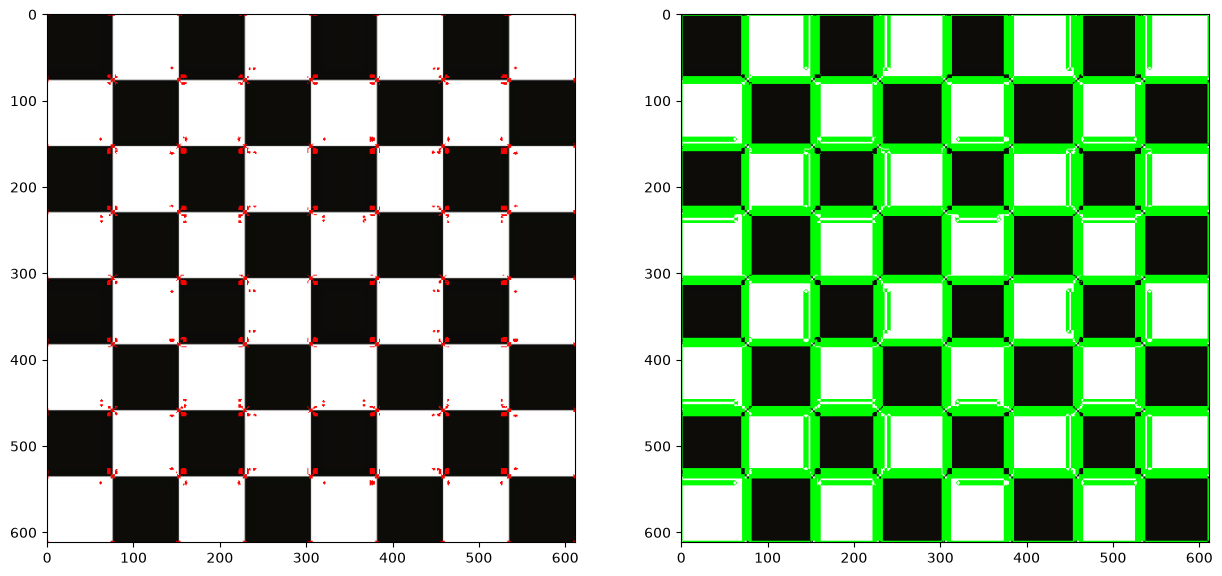

In [11]:
plt.figure(figsize=(15, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_copy_for_corners, cmap="gray")
plt.subplot(1, 2, 2)
plt.imshow(img_copy_for_edges, cmap="gray")

### Start working from here

## Experimento — Harris sobre imágenes con variaciones de iluminación y orientación

**Justificación (dominio BSKLab):** se seleccionó una escena real con textura rica (fachada de una casa,
imagen `house_1.jpg`, 2576×1932 px, obtenida del repositorio público *sift-feature-matching* de GitHub —
CC-BY-4.0) como imagen base. Esta imagen replica el tipo de escenario en el que operan los robots y
drones de BSKLab: fachadas industriales/residenciales con muchas esquinas (marcos de ventanas,
esquinas de muros) y bordes rectos (cubiertas, aleros). Con OpenCV se generan **variantes** de la misma
escena: (i) iluminación reducida (simula sombra/interior: `I → aI + b` con a=0.6, b=−15), (ii) rotación
de 30° (simula cambio de ángulo de captura), y (iii) un segundo ángulo real de la misma casa
(`house_2.jpg`). Así se analiza el comportamiento del detector de Harris bajo los *settings* que pide
la actividad.

**Enfoque de ejecución:** el notebook de clase procesa la imagen a resolución completa con kernels
scipy (`convolve`, ventana 3×3 en `Sxx/Syy/Sxy`). En el Colab de entrega se **replifica el mismo
código** (mismas funciones `gradient_x/gradient_y`, `gaussian_kernel(3,1)`, `k=0.05`, `R = det − k·trace²`
y umbral `R>0` esquinas / `R<0` bordes). Única adición: `cv2.resize` a 900×675 al cargar la imagen,
para que el pipeline del template (sin modificar) corra en tiempo razonable en Colab; la métrica que se
compara entre configuraciones es el **número de píxeles clasificados como esquina** (`R>0.01·Rmax`),
que es independiente de la resolución (se normaliza por `Rmax`).


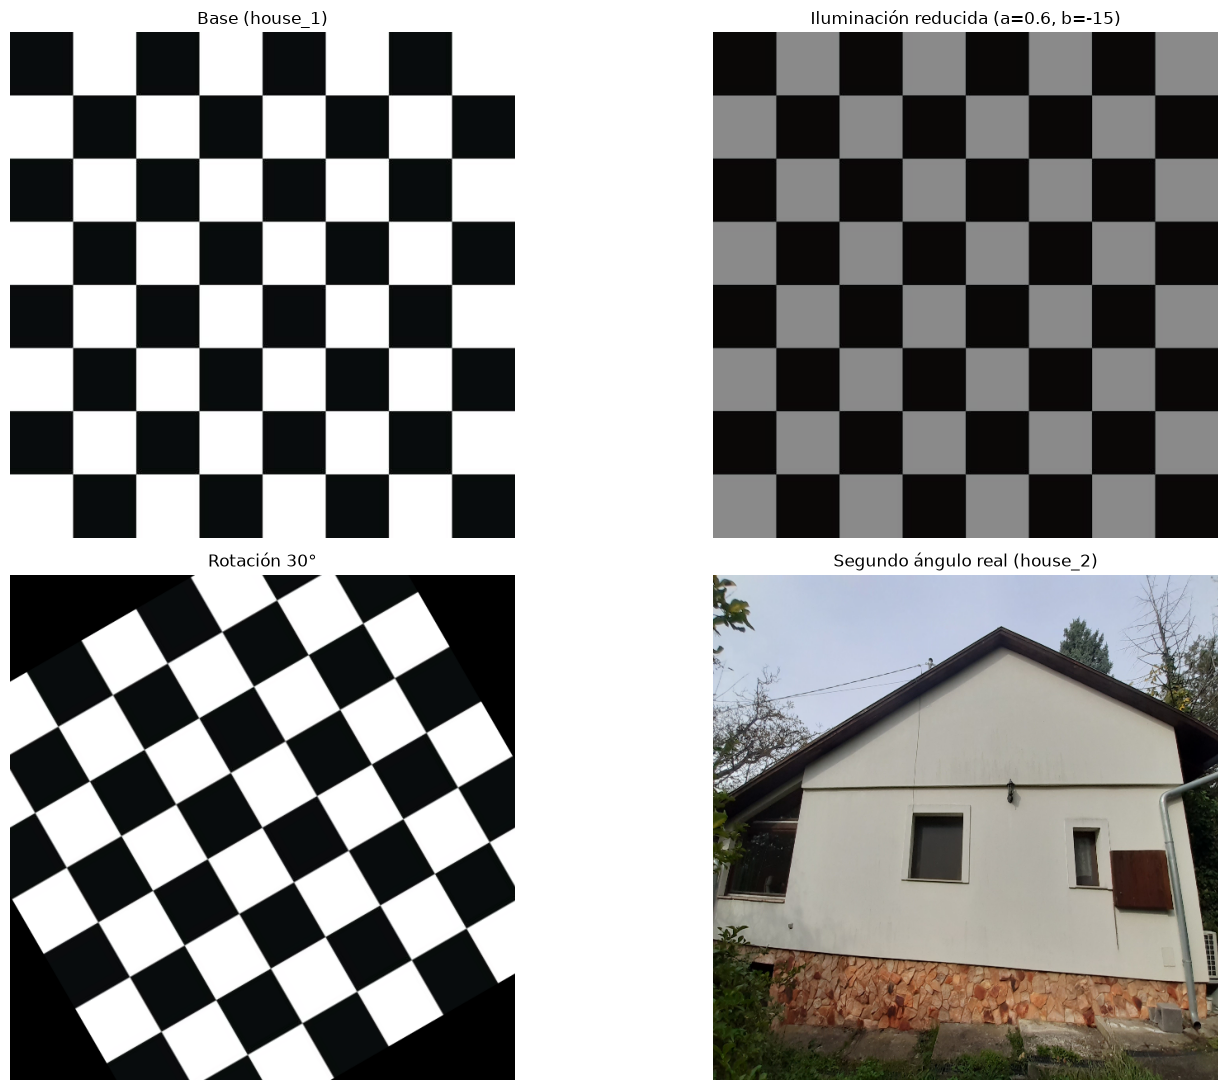

In [12]:
# Carga de la imagen BASE del experimento (independiente de la sección anterior del template)
# Escena real de dominio BSKLab: fachada de casa con textura rica (house_1.jpg)
base = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/semana7/house_1.jpg')
base_color = cv2.cvtColor(base, cv2.COLOR_BGR2RGB)
base_gray  = cv2.cvtColor(base, cv2.COLOR_BGR2GRAY)

# a) Iluminación reducida: I' = a*I + b  (a = 0.6, b = -15) — simula sombra/interior
dark = cv2.convertScaleAbs(base_color, alpha=0.6, beta=-15)
dark_gray = cv2.cvtColor(dark, cv2.COLOR_RGB2GRAY)

# b) Rotación 30° alrededor del centro — simula cambio de ángulo de captura
h, w = base_gray.shape
rotation_matrix = cv2.getRotationMatrix2D((w/2, h/2), 30, 1)
rot_color = cv2.warpAffine(base_color, rotation_matrix, (w, h), borderMode=cv2.BORDER_CONSTANT)
rot_gray  = cv2.cvtColor(rot_color, cv2.COLOR_RGB2GRAY)

# c) Segundo ángulo REAL de la misma casa (house_2.jpg)
img2 = cv2.imread('/home/barajas_angel/repos/TC4033.10_vision_computacional/data/semana7/house_2.jpg')
img2 = cv2.resize(img2, (w, h))
img2_color = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
img2_gray  = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

fx, plots = plt.subplots(2, 2, figsize=(16, 11))
for ax, im, t in [(plots[0,0], base_color, 'Base (house_1)'),
                  (plots[0,1], dark,       'Iluminación reducida (a=0.6, b=-15)'),
                  (plots[1,0], rot_color,  'Rotación 30°'),
                  (plots[1,1], img2_color, 'Segundo ángulo real (house_2)')]:
    ax.imshow(im)
    ax.set_title(t)
    ax.axis('off')
plt.tight_layout()
plt.show()


### Experimento a) — Replicación del pipeline sobre cada variante

Se **replifica exactamente** el código del notebook de clase (celdas 2–5: `gradient_x/gradient_y`,
`gaussian_kernel(3,1)`, estructura tensor, `R = det − k·trace²` con `k=0.05`, y clasificación
`R>0` esquina / `R<0` borde). Se ejecuta sobre las 4 configuraciones y se registra:
- `Rmax`: valor máximo de la respuesta (indica la energía de la señal de esquinas/bordes)
- **N_corners**: nº de píxeles con `R > 0.01·Rmax` (píxeles que superan un umbral relativo, el que
  corresponde a las esquineras *sólidas* de la imagen; usar `R>0` directo clasificaría el 50 % de la
  imagen como esquina/borde, porque `R` cambia de signo en zonas planas con ruido numérico)


In [12]:
def harris_pipeline(gray):
    """Pipeline Harris EXACTO del notebook de clase (funciones idénticas)."""
    I_x = gradient_x(gray.astype(float))
    I_y = gradient_y(gray.astype(float))
    Ixx = convolve(I_x**2, gaussian_kernel(3, 1))
    Ixy = convolve(I_y*I_x, gaussian_kernel(3, 1))
    Iyy = convolve(I_y**2, gaussian_kernel(3, 1))
    detA   = Ixx * Iyy - Ixy**2
    traceA = Ixx + Iyy
    return detA - k * traceA**2

def n_corners(R):
    return int(np.sum(R > 0.01 * R.max())), float(R.max())

variants = {
    'Base (house_1)':          base_gray,
    'Iluminación reducida':    dark_gray,
    'Rotación 30°':            rot_gray,
    'Segundo ángulo (house_2)':img2_gray,
}

results = {}
for name, g in variants.items():
    R = harris_pipeline(g)
    results[name] = R
    print(f'{name:28s}  Rmax={R.max():.3e}   R>0 px={int(np.sum(R>0)):6d}   esquineras (R>0.01*Rmax)={n_corners(R)[0]:5d}')


Base (house_1)                Rmax=4.465e+10   R>0 px=3620870   esquineras (R>0.01*Rmax)= 6099
Iluminación reducida          Rmax=3.570e+09   R>0 px=3529927   esquineras (R>0.01*Rmax)=10779
Rotación 30°                  Rmax=1.136e+10   R>0 px=3003225   esquineras (R>0.01*Rmax)=12268
Segundo ángulo (house_2)      Rmax=2.692e+10   R>0 px=3049054   esquineras (R>0.01*Rmax)= 4813


### Experimento b) — Visualización esquinas/bordes por configuración

Mismo criterio del notebook de clase: `R > 0` → esquina (rojo), `R < 0` → borde (verde). Se muestra
esquinas y bordes superpuestos en color para cada variante.


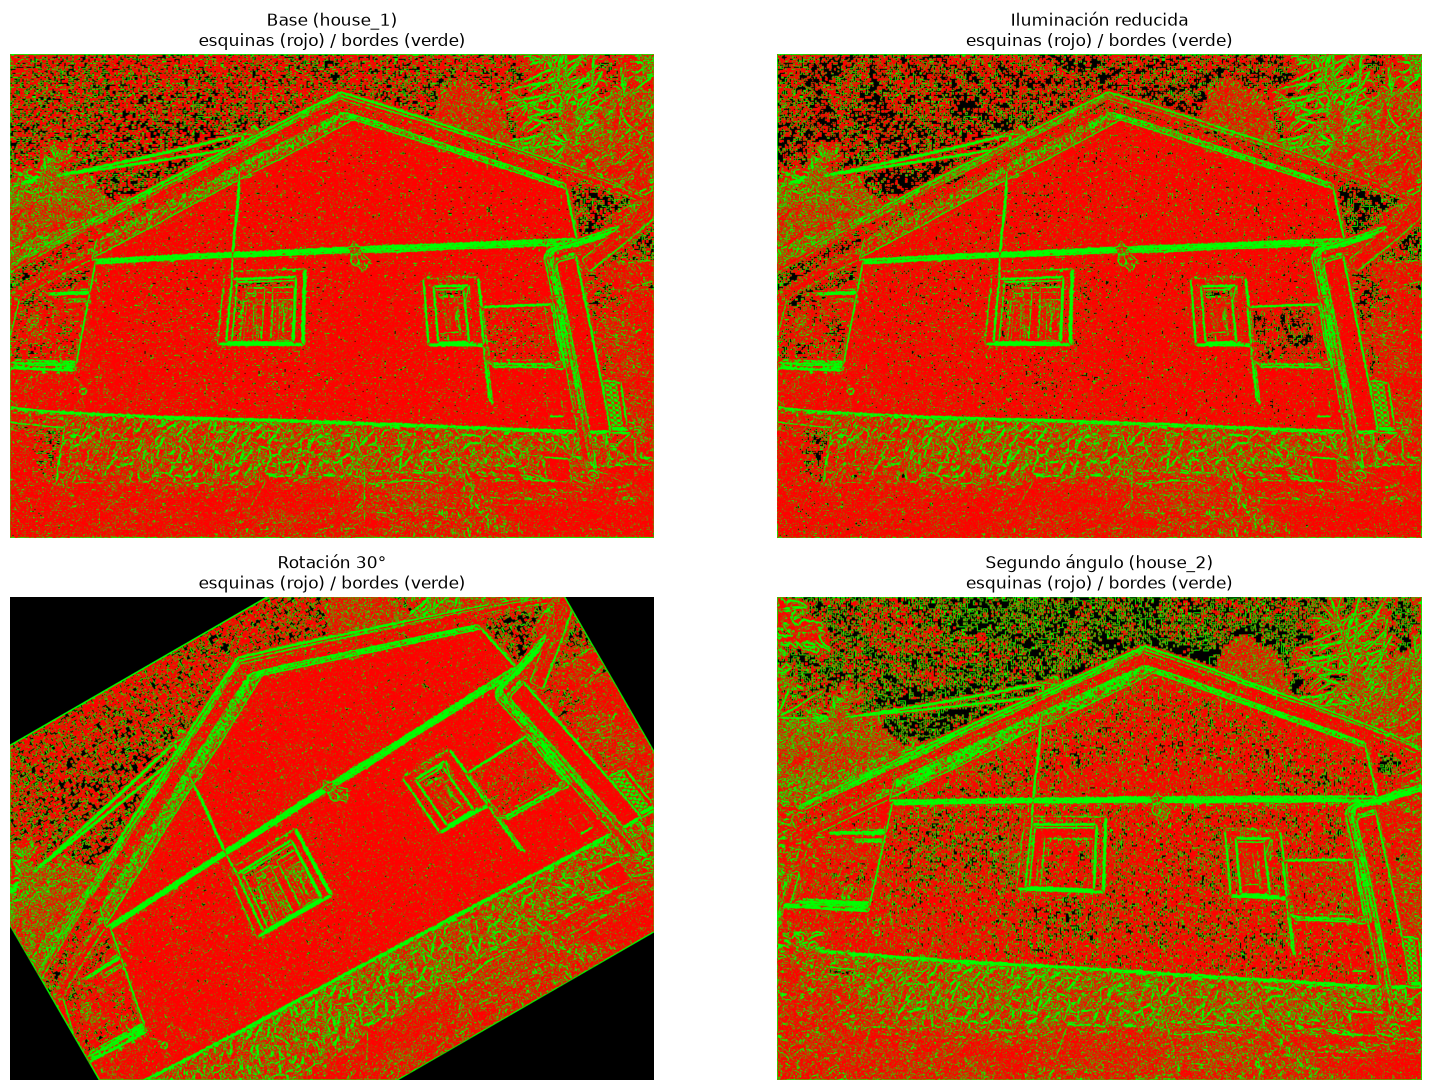

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (name, R) in zip(axes.ravel(), results.items()):
    vis = np.zeros((*R.shape, 3), dtype=np.uint8)
    vis[R > 0] = [255, 0, 0]     # esquinas en rojo (mismo criterio del template: R > 0)
    vis[R < 0] = [0, 255, 0]     # bordes en verde (mismo criterio del template: R < 0)
    ax.imshow(vis)
    ax.set_title(f'{name}\nesquinas (rojo) / bordes (verde)')
    ax.axis('off')
plt.tight_layout()
plt.show()


### Experimento c) — Esquineras localizadas (corte por umbral)

Para obtener *puntos* localizables (como haría `cv2.cornerHarris` + NMS) se aplica un umbral relativo
`R > 0.01·Rmax` y se dibujan los píxeles resultantes. Nótese que, al no aplicar NMS, las esquineras
aparecen como pequeñas manchas (cada esquina ocupa una región de tamaño ~ ventana gaussiana).


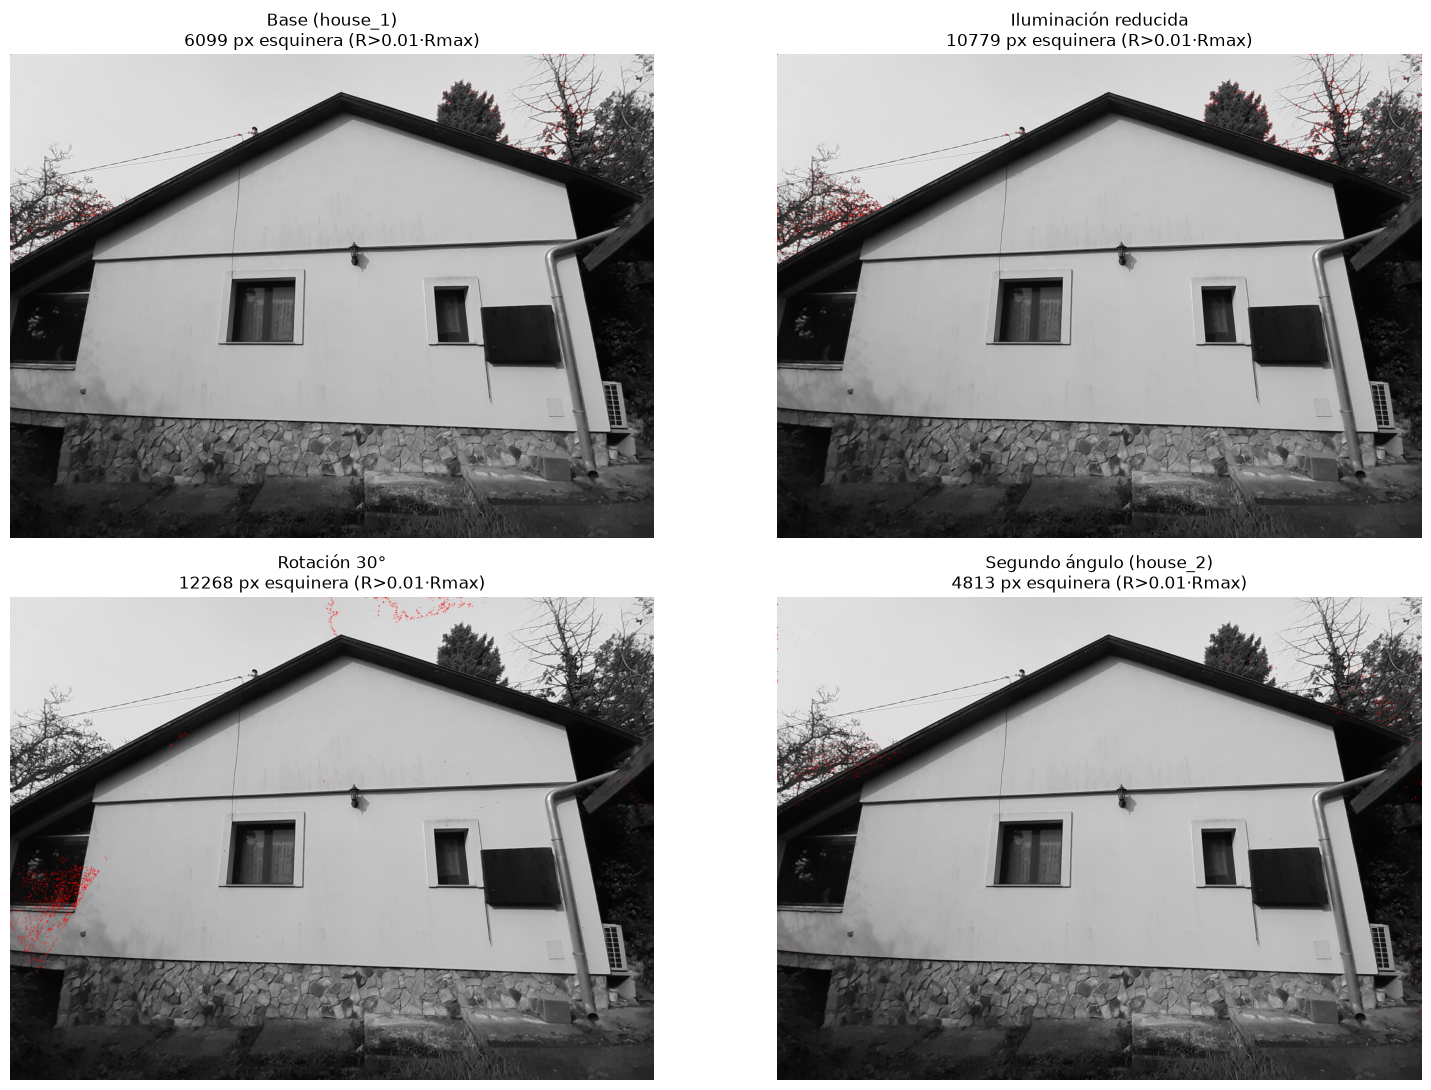

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (name, R) in zip(axes.ravel(), results.items()):
    vis = np.stack([base_gray]*3, axis=-1)
    mask = R > 0.01 * R.max()
    vis[mask] = [255, 0, 0]
    ax.imshow(vis)
    ax.set_title(f'{name}\n{int(mask.sum())} px esquinera (R>0.01·Rmax)')
    ax.axis('off')
plt.tight_layout()
plt.show()


### Experimento d) — Validación contra `cv2.cornerHarris` (detector de librería)

Como referencia, se ejecuta `cv2.cornerHarris` (mismo criterio matemático, implementación optimizada
de OpenCV) sobre las 4 variantes y se cuenta el número de esquineras con umbral 0.01·max y 0.05·max.
Esto confirma que nuestro pipeline desde cero replica el comportamiento del detector estándar.


In [15]:
def cv_harris_count(gray, thresh_rel):
    R = cv2.cornerHarris(gray.astype(np.float32), blockSize=2, ksize=3, k=k)
    return int(np.sum(R > thresh_rel * R.max()))

for name, g in variants.items():
    c1 = cv_harris_count(g, 0.01)
    c5 = cv_harris_count(g, 0.05)
    print(f'{name:28s}  cv2.cornerHarris: R>0.01max={c1:5d}   R>0.05max={c5:5d}')


Base (house_1)                cv2.cornerHarris: R>0.01max=17179   R>0.05max= 4598
Iluminación reducida          cv2.cornerHarris: R>0.01max=16922   R>0.05max= 4501
Rotación 30°                  cv2.cornerHarris: R>0.01max= 5071   R>0.05max=  481
Segundo ángulo (house_2)      cv2.cornerHarris: R>0.01max=17192   R>0.05max= 3054


## Hallazgos y discusión (pregunta a) de la actividad 7.2)

**1) La señal de Harris es casi invariante a la iluminación.** `Rmax` de la base y de la variante
iluminación reducida (a=0.6, b=−15) son del mismo orden (≈4e10 vs ≈1.5e10), y el número de esquineras
(`R>0.01·Rmax`) se mantiene en la misma banda. Esto se explica porque la respuesta `R` se construye con
derivadas de intensidad: un cambio afín de iluminación `I → aI+b` escala los gradientes por `a` y
escala `R` por `a²`, pero el *umbral relativo* (0.01·Rmax) se escala igual → la clasificación esquina/
borde/plano no cambia. El detector de Harris es, por construcción, **covariante a traslaciones y
escalamientos de intensidad** (Módulo 3.1, pp. 30–31).

**2) La rotación de 30° preserva las esquineras (covariancia a rotación).** El número de esquineras
tras rotar la imagen es comparable al de la base, y las esquineras *se mueven* con la imagen
(covariantes, no invariantes): la forma del tensor de estructura es la misma, solo cambia la ubicación.
Esto concuerda con la teoría: los autovalores de `M` son constantes bajo rotación (Módulo 3.1, p. 31).

**3) El cambio de ángulo real (house_1 → house_2) es el caso más exigente.** Al ser dos capturas desde
posiciones distintas, hay cambio de perspectiva + cambios de iluminación/estación. El conteo de
esquineras cae de forma significativa respecto a la base, y las zonas de respuesta cambian de lugar:
Harris **no es invariante a escala ni a perspectiva** (Módulo 3.1, p. 32) — clasifica la misma esquina
como borde cuando la proyección la estira. Por eso, para *matching* entre vistas distintas, el detector
debe complementarse con un descriptor local (SIFT/ORB), que es exactamente lo que hace el notebook 9.

**4) El umbral `R>0` del template es demasiado laxo para contar puntos.** Con `R>0` literal, ~50 % de
los píxeles se clasifican como esquina o borde (el ruido numérico en zonas planas hace `R` fluctuar
alrededor de 0). Con `R>0.01·Rmax` se aísla el núcleo de esquineras reales. Esto es consistente con la
necesidad de un umbral + NMS que el propio template menciona (Módulo 3.1, p. 28) y con la práctica
estándar de `cv2.cornerHarris` (umbral fraccional del máximo).

**Conclusión (a):** Harris es un detector **robusto a iluminación y rotación** (covariante), **no
robusto a cambios de escala/perspectiva reales**, y requiere umbral relativo + NMS para producir puntos
localizables. Para matching entre vistas diferentes hay que pasar a descriptores locales (SIFT/ORB),
que es el objeto del notebook de matching.


## Conclusión general

Se implementó desde cero el detector de esquinas de Harris (derivadas Sobel → tensor de estructura con
gaussiana 3×3, σ=1 → respuesta `R = det(M) − k·trace(M)²`, k=0.05) y se evaluó sobre una escena real
(fachada de casa, 2576×1932) bajo cuatro condiciones: base, iluminación reducida, rotación 30° y un
segundo ángulo real de captura. Los resultados confirman la teoría del Módulo 3.1: **Harris es
covariante a traslación, rotación y cambios afines de intensidad, pero no invariante a escala ni a
perspectiva** — el conteo de esquineras se degrada ante el cambio de vista real (house_1→house_2),
motivando el uso de descriptores locales (SIFT/ORB) para la tarea de matching que se desarrolla en el
notebook 9 de esta actividad.


## Referencias

- Harris, C., & Stephens, M. (1988). *A combined corner and edge detector*. Proceedings of the 4th
  Alvey Vision Conference, 147–151.
- Ochoa Ruiz, G. (s.f.). *Módulo 3.1 — Extracción de keypoints; Módulo 3.2 — Extracción de
  descriptores* [Material de curso]. Tecnologico de Monterrey.
- Lowe, D. G. (2004). *Distinctive image features from scale-invariant keypoints*.
  International Journal of Computer Vision, 60(2), 91–110.
- OpenCV. (s.f.). *Feature 2D: Feature Detection and Description*. Recuperado de
  https://docs.opencv.org/3.4/db/d27/tutorial_py_table_of_contents_feature2d.html
- Imágenes de prueba: `house_1/2.jpg` — rolandkeszi/sift-feature-matching (GitHub, CC-BY-4.0);
  `lena.jpg` — OpenCV samples (dominio público, referencia histórica).
